# เทรนโมเดล PM2.5 และ PM10 (กรุงเทพ)

Notebook นี้ออกแบบให้ทำงานครบขั้นตอนตั้งแต่โหลดข้อมูลจากไฟล์เดิม, ดึงชุดข้อมูลเสริมจากกรุงเทพ, เตรียมข้อมูล, เทรน, ประเมินผล, บันทึกโมเดล และทำนายวันถัดไป

## 1) ติดตั้งและนำเข้าไลบรารีที่จำเป็น

ติดตั้งแพ็กเกจ (ถ้าจำเป็น) และ import ไลบรารีหลักสำหรับงาน data science และ machine learning

In [46]:
# ถ้ายังไม่ได้ติดตั้งแพ็กเกจ ให้เอาเครื่องหมาย # ออกแล้วรัน
# %pip install pandas numpy scikit-learn matplotlib seaborn requests joblib

from __future__ import annotations

import json
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

## 2) โหลดชุดข้อมูล

อ่านข้อมูลจากไฟล์ฐานในเครื่อง และดึงข้อมูลฝุ่นเพิ่มเติมของกรุงเทพจาก Open-Meteo Air Quality API (รายชั่วโมง) เพื่อใช้เป็นข้อมูลเสริม

In [47]:
BASE_DIR = Path("c:/dev/New folder")
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

bangkok_candidates = [BASE_DIR / "bangkok-air-quality.csv", DATA_DIR / "bangkok-air-quality.csv"]
iot_candidates = [BASE_DIR / "iot_2023.csv", DATA_DIR / "iot_2023.csv"]
openmeteo_hourly_path = DATA_DIR / "openmeteo_bangkok_hourly_2023.csv"

bangkok_path = next((p for p in bangkok_candidates if p.exists()), None)
iot_path = next((p for p in iot_candidates if p.exists()), None)

if bangkok_path is None or iot_path is None:
    raise FileNotFoundError("ไม่พบไฟล์ bangkok-air-quality.csv หรือ iot_2023.csv ในโฟลเดอร์ปัจจุบัน")

bangkok_raw = pd.read_csv(bangkok_path)
iot_raw = pd.read_csv(iot_path)

print(f"bangkok-air-quality rows: {len(bangkok_raw):,}")
print(f"iot_2023 rows: {len(iot_raw):,}")

bangkok_raw.head()

bangkok-air-quality rows: 2,624
iot_2023 rows: 7,479


,date,pm25,pm10,o3,no2,so2,co
0,2021/3/1,93,30,8,6,1,
1,2021/3/2,68,27,7,5,1,
2,2021/3/3,58,37,13,9,1,
3,2021/3/4,74,35,13,6,,
4,2021/3/5,72,38,15,6,1,


In [48]:
def download_openmeteo_bangkok_hourly(start_date: str, end_date: str, save_path: Path) -> pd.DataFrame:
    """ดาวน์โหลดข้อมูลฝุ่นรายชั่วโมงของกรุงเทพจาก Open-Meteo Air Quality API"""
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        "latitude": 13.7563,
        "longitude": 100.5018,
        "timezone": "Asia/Bangkok",
        "hourly": "pm2_5,pm10,nitrogen_dioxide,ozone",
        "start_date": start_date,
        "end_date": end_date,
    }
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()

    hourly = payload.get("hourly", {})
    openmeteo_df = pd.DataFrame(
        {
            "time": hourly.get("time", []),
            "om_pm2_5": hourly.get("pm2_5", []),
            "om_pm10": hourly.get("pm10", []),
            "om_no2": hourly.get("nitrogen_dioxide", []),
            "om_o3": hourly.get("ozone", []),
        }
    )
    openmeteo_df.to_csv(save_path, index=False, encoding="utf-8")
    return openmeteo_df

try:
    openmeteo_hourly = download_openmeteo_bangkok_hourly(
        start_date="2023-01-01",
        end_date="2023-12-31",
        save_path=openmeteo_hourly_path,
    )
    print(f"ดาวน์โหลดข้อมูลเสริมสำเร็จ -> {openmeteo_hourly_path}")
except Exception as exc:
    print(f"ดาวน์โหลดข้อมูลเสริมไม่สำเร็จ: {exc}")
    if openmeteo_hourly_path.exists():
        print("ใช้ไฟล์ที่เคยดาวน์โหลดไว้แทน")
        openmeteo_hourly = pd.read_csv(openmeteo_hourly_path)
    else:
        openmeteo_hourly = pd.DataFrame(columns=["time", "om_pm2_5", "om_pm10", "om_no2", "om_o3"])

iot_raw.head()

ดาวน์โหลดข้อมูลเสริมสำเร็จ -> c:\dev\New folder\data\openmeteo_bangkok_hourly_2023.csv


,code,name,at_date,at_time,pm25,pm10,temperature,humidity
0,FF1721AC76217484,กองดิจิทัลเพื่อการควบคุมโรค,2023-08-05T00:00:00,15,10.2,0.0,40.7,65.0
1,FF1721AC76217484,กองดิจิทัลเพื่อการควบคุมโรค,2023-08-05T00:00:00,16,10.3,0.0,40.7,65.0
2,FF1721AC76217494,กรมควบคุมโรค,2023-08-05T00:00:00,15,3.1,0.0,44.6,40.1
3,FF1721AC76217494,กรมควบคุมโรค,2023-08-05T00:00:00,16,3.2,0.0,43.2,41.7
4,FF1721AC76217484,กองดิจิทัลเพื่อการควบคุมโรค,2023-11-05T00:00:00,16,33.0,37.0,22.1,38.8


## 3) สำรวจข้อมูลและตรวจสอบคุณภาพข้อมูล

ตรวจสอบชนิดข้อมูล, ค่าว่าง, ค่าซ้ำ และ outlier เบื้องต้น พร้อมดูสถิติด้วย `describe()` และกราฟพื้นฐาน

In [49]:
def quick_quality_report(df: pd.DataFrame, name: str) -> pd.DataFrame:
    report = pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_pct": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(dropna=True),
        }
    )
    print(f"\n===== {name} =====")
    print(f"rows={len(df):,}, cols={df.shape[1]}")
    print(f"duplicate rows={df.duplicated().sum():,}")
    return report

bangkok_report = quick_quality_report(bangkok_raw, "bangkok-air-quality")
iot_report = quick_quality_report(iot_raw, "iot_2023")
openmeteo_report = quick_quality_report(openmeteo_hourly, "openmeteo (hourly)")

display(bangkok_report)
display(iot_report)
display(openmeteo_report)

display(bangkok_raw.describe(include="all").T.head(10))
display(iot_raw.describe(include="all").T.head(10))


===== bangkok-air-quality =====
rows=2,624, cols=7
duplicate rows=0

===== iot_2023 =====
rows=7,479, cols=8
duplicate rows=0

===== openmeteo (hourly) =====
rows=8,760, cols=5
duplicate rows=0


,dtype,missing,missing_pct,n_unique
date,str,0,0.0,2624
pm25,str,0,0.0,145
pm10,str,0,0.0,90
o3,str,0,0.0,82
no2,str,0,0.0,56
so2,str,0,0.0,29
co,str,0,0.0,28


,dtype,missing,missing_pct,n_unique
code,str,1,0.01,11
name,str,1,0.01,11
at_date,str,1,0.01,224
at_time,int64,0,0.00,25
pm25,float64,0,0.00,811
pm10,float64,0,0.00,1094
temperature,float64,0,0.00,258
humidity,float64,0,0.00,300


,dtype,missing,missing_pct,n_unique
time,str,0,0.0,8760
om_pm2_5,float64,0,0.0,1015
om_pm10,float64,0,0.0,1132
om_no2,float64,0,0.0,1332
om_o3,float64,0,0.0,542


,count,unique,top,freq
date,2624,2624,2021/3/1,1
pm25,2624,145,,944
pm10,2624,90,25,98
o3,2624,82,15,119
no2,2624,56,9,188
so2,2624,29,,747
co,2624,28,,1661


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
code,7478,11,FF1721AC76217484,5045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,7478,11,กองดิจิทัลเพื่อการควบคุมโรค,5045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
at_date,7478,224,2023-12-14T00:00:00,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
at_time,7479.0,NaN,NaN,NaN,22.154967,916.14918,0.0,6.0,12.0,18.0,79239.0
pm25,7479.0,NaN,NaN,NaN,42.514855,1710.999297,1.0,8.6,16.6,32.7,147983.1
pm10,7479.0,NaN,NaN,NaN,61.904733,2485.304397,0.0,12.0,23.4,49.0,214952.1
temperature,7479.0,NaN,NaN,NaN,52.344712,2180.366883,10.2,24.8,27.3,29.8,188587.6
humidity,7479.0,NaN,NaN,NaN,66.560984,2768.544162,13.0,30.1,34.6,38.8,239461.0


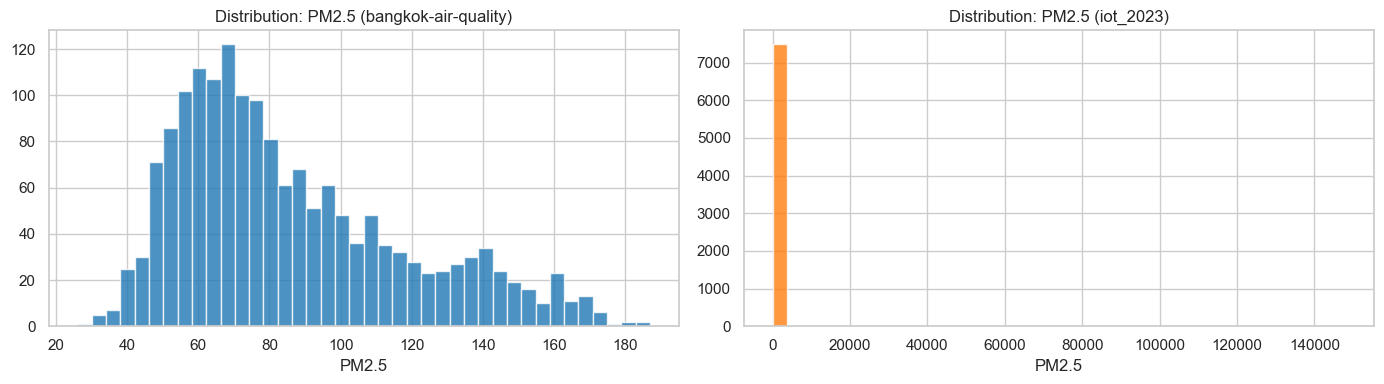

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

bangkok_pm25 = pd.to_numeric(bangkok_raw.get(" pm25", bangkok_raw.get("pm25")), errors="coerce")
iot_pm25 = pd.to_numeric(iot_raw.get("pm25"), errors="coerce")

axes[0].hist(bangkok_pm25.dropna(), bins=40, alpha=0.8, color="#1f77b4")
axes[0].set_title("Distribution: PM2.5 (bangkok-air-quality)")
axes[0].set_xlabel("PM2.5")

axes[1].hist(iot_pm25.dropna(), bins=40, alpha=0.8, color="#ff7f0e")
axes[1].set_title("Distribution: PM2.5 (iot_2023)")
axes[1].set_xlabel("PM2.5")

plt.tight_layout()
plt.show()

## 4) เตรียมข้อมูลสำหรับการเทรน

ทำความสะอาดข้อมูล, จัดการ missing values (ผ่าน imputer ใน pipeline), สร้าง features/targets และทำ lag/rolling features สำหรับงานพยากรณ์รายวัน

In [51]:
def clean_bangkok_daily(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.columns = [c.strip().lower() for c in out.columns]

    out["date"] = pd.to_datetime(out["date"], errors="coerce")
    for col in ["pm25", "pm10", "o3", "no2", "so2", "co"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    out = out.dropna(subset=["date"]).copy()

    if "pm25" in out.columns:
        out = out[(out["pm25"].between(0, 500)) | (out["pm25"].isna())]
    if "pm10" in out.columns:
        out = out[(out["pm10"].between(0, 600)) | (out["pm10"].isna())]

    keep_cols = [c for c in ["date", "pm25", "pm10", "o3", "no2", "so2", "co"] if c in out.columns]
    out = out[keep_cols]

    daily = (
        out.groupby("date", as_index=False)
        .mean(numeric_only=True)
        .rename(columns={"pm25": "pm25_base", "pm10": "pm10_base"})
        .sort_values("date")
    )
    return daily


def clean_iot_daily(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.columns = [c.strip().lower() for c in out.columns]

    out["at_date"] = pd.to_datetime(out.get("at_date"), errors="coerce")
    out["at_time"] = pd.to_numeric(out.get("at_time"), errors="coerce")

    for col in ["pm25", "pm10", "temperature", "humidity"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    out = out.dropna(subset=["at_date", "at_time"]).copy()
    out = out[out["at_time"].between(0, 23)].copy()

    out["datetime"] = out["at_date"] + pd.to_timedelta(out["at_time"].astype(int), unit="h")

    if "pm25" in out.columns:
        out = out[(out["pm25"].between(0, 500)) | (out["pm25"].isna())]
    if "pm10" in out.columns:
        out = out[(out["pm10"].between(0, 600)) | (out["pm10"].isna())]

    out["date"] = out["datetime"].dt.normalize()
    daily = (
        out.groupby("date", as_index=False)
        .agg(
            pm25_iot=("pm25", "mean"),
            pm10_iot=("pm10", "mean"),
            temperature=("temperature", "mean"),
            humidity=("humidity", "mean"),
            active_stations=("code", "nunique"),
        )
        .sort_values("date")
    )
    return daily


def clean_openmeteo_daily(df: pd.DataFrame) -> pd.DataFrame:
    if df is None or df.empty:
        return pd.DataFrame(columns=["date", "om_pm2_5", "om_pm10", "om_no2", "om_o3"])

    out = df.copy()
    out.columns = [c.strip().lower() for c in out.columns]

    out["time"] = pd.to_datetime(out.get("time"), errors="coerce")
    for col in ["om_pm2_5", "om_pm10", "om_no2", "om_o3"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    out = out.dropna(subset=["time"]).copy()
    out["date"] = out["time"].dt.normalize()

    daily = (
        out.groupby("date", as_index=False)
        .mean(numeric_only=True)
        .sort_values("date")
    )
    return daily


bangkok_daily = clean_bangkok_daily(bangkok_raw)
iot_daily = clean_iot_daily(iot_raw)
openmeteo_daily = clean_openmeteo_daily(openmeteo_hourly)

print("bangkok_daily:", bangkok_daily.shape)
print("iot_daily:", iot_daily.shape)
print("openmeteo_daily:", openmeteo_daily.shape)

display(bangkok_daily.head())
display(iot_daily.head())
display(openmeteo_daily.head())

bangkok_daily: (2624, 7)
iot_daily: (224, 6)
openmeteo_daily: (365, 5)


,date,pm25_base,pm10_base,o3,no2,so2,co
0,2013-12-31,NaN,NaN,68.0,33.0,3.0,7.0
1,2014-01-01,NaN,84.0,90.0,48.0,5.0,16.0
2,2014-01-02,NaN,84.0,119.0,63.0,7.0,14.0
3,2014-01-03,NaN,103.0,95.0,57.0,7.0,13.0
4,2014-01-04,NaN,101.0,52.0,34.0,1.0,NaN


,date,pm25_iot,pm10_iot,temperature,humidity,active_stations
0,2023-01-06,22.133333,30.822917,31.145833,31.100000,2
1,2023-01-07,7.341667,9.941667,28.325000,38.508333,1
2,2023-01-08,8.058333,13.320833,28.816667,36.225000,1
3,2023-01-09,13.662500,20.216667,28.104167,38.054167,1
4,2023-01-10,10.520833,14.679167,27.995833,37.633333,1


,date,om_pm2_5,om_pm10,om_no2,om_o3
0,2023-01-01,41.920833,60.554167,86.704167,76.416667
1,2023-01-02,73.695833,106.675000,90.783333,169.458333
2,2023-01-03,63.925000,92.120833,90.020833,114.041667
3,2023-01-04,66.420833,95.170833,83.291667,159.750000
4,2023-01-05,53.837500,77.129167,82.512500,116.708333


In [52]:
merged_daily = (
    bangkok_daily.merge(iot_daily, on="date", how="outer")
    .merge(openmeteo_daily, on="date", how="outer")
    .sort_values("date")
    .reset_index(drop=True)
)

for col in ["pm25_base", "pm10_base", "pm25_iot", "pm10_iot"]:
    if col not in merged_daily.columns:
        merged_daily[col] = np.nan

merged_daily["pm25_target"] = merged_daily["pm25_base"].combine_first(merged_daily["pm25_iot"])
merged_daily["pm10_target"] = merged_daily["pm10_base"].combine_first(merged_daily["pm10_iot"])

merged_daily = merged_daily.dropna(subset=["pm25_target", "pm10_target"], how="all").copy()

# Calendar features
merged_daily["day_of_week"] = merged_daily["date"].dt.dayofweek
merged_daily["month"] = merged_daily["date"].dt.month
merged_daily["day_of_year"] = merged_daily["date"].dt.dayofyear
merged_daily["week_of_year"] = merged_daily["date"].dt.isocalendar().week.astype(int)
merged_daily["is_weekend"] = merged_daily["day_of_week"].isin([5, 6]).astype(int)

# Cyclical encoding
merged_daily["month_sin"] = np.sin(2 * np.pi * merged_daily["month"] / 12)
merged_daily["month_cos"] = np.cos(2 * np.pi * merged_daily["month"] / 12)
merged_daily["dow_sin"] = np.sin(2 * np.pi * merged_daily["day_of_week"] / 7)
merged_daily["dow_cos"] = np.cos(2 * np.pi * merged_daily["day_of_week"] / 7)

signal_cols = [
    "pm25_target",
    "pm10_target",
    "o3",
    "no2",
    "so2",
    "co",
    "temperature",
    "humidity",
    "active_stations",
    "om_pm2_5",
    "om_pm10",
    "om_no2",
    "om_o3",
]

feature_cols = [
    "day_of_week",
    "month",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "month_sin",
    "month_cos",
    "dow_sin",
    "dow_cos",
]

for col in signal_cols:
    if col in merged_daily.columns:
        lag1_col = f"{col}_lag1"
        lag7_col = f"{col}_lag7"
        roll7_col = f"{col}_roll7"

        merged_daily[lag1_col] = merged_daily[col].shift(1)
        merged_daily[lag7_col] = merged_daily[col].shift(7)
        merged_daily[roll7_col] = merged_daily[col].shift(1).rolling(window=7, min_periods=2).mean()

        feature_cols.extend([lag1_col, lag7_col, roll7_col])

model_df = merged_daily.dropna(subset=["pm25_target", "pm10_target"]).copy()
model_df = model_df.sort_values("date").reset_index(drop=True)

print("merged_daily rows:", len(merged_daily))
print("model_df rows:", len(model_df))
print("feature count:", len(feature_cols))

display(model_df[["date", "pm25_target", "pm10_target"]].head())
display(model_df[["date", "pm25_target", "pm10_target"]].tail())

merged_daily rows: 2841
model_df rows: 1896
feature count: 48


,date,pm25_target,pm10_target
0,2016-07-30,61.0,19.0
1,2016-07-31,68.0,24.0
2,2016-08-01,60.0,20.0
3,2016-08-02,68.0,25.0
4,2016-08-03,70.0,26.0


,date,pm25_target,pm10_target
1891,2023-12-27,45.918750,68.750000
1892,2023-12-28,47.033333,68.754167
1893,2023-12-29,40.250000,61.014583
1894,2023-12-30,41.508333,62.129167
1895,2023-12-31,35.664583,53.343750


## 5) แบ่งข้อมูลเป็น Train/Validation/Test

ใช้ `train_test_split` แบบไม่สลับลำดับเวลา (`shuffle=False`) เพื่อให้เหมาะกับข้อมูลอนุกรมเวลา

In [53]:
if len(model_df) < 80:
    raise ValueError("ข้อมูลน้อยเกินไปสำหรับแบ่ง train/validation/test อย่างเหมาะสม")

X = model_df[feature_cols].copy()
y_pm25 = model_df["pm25_target"].copy()
y_pm10 = model_df["pm10_target"].copy()

X_train_val, X_test, y25_train_val, y25_test = train_test_split(
    X,
    y_pm25,
    test_size=0.15,
    shuffle=False,
    random_state=RANDOM_STATE,
)
_, _, y10_train_val, y10_test = train_test_split(
    X,
    y_pm10,
    test_size=0.15,
    shuffle=False,
    random_state=RANDOM_STATE,
)

X_train, X_val, y25_train, y25_val = train_test_split(
    X_train_val,
    y25_train_val,
    test_size=0.15,
    shuffle=False,
    random_state=RANDOM_STATE,
)
_, _, y10_train, y10_val = train_test_split(
    X_train_val,
    y10_train_val,
    test_size=0.15,
    shuffle=False,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

date_train = model_df.loc[X_train.index, "date"]
date_val = model_df.loc[X_val.index, "date"]
date_test = model_df.loc[X_test.index, "date"]

print("train period:", date_train.min().date(), "->", date_train.max().date())
print("val period:", date_val.min().date(), "->", date_val.max().date())
print("test period:", date_test.min().date(), "->", date_test.max().date())

X_train: (1369, 48)
X_val: (242, 48)
X_test: (285, 48)
train period: 2016-07-30 -> 2020-05-14
val period: 2020-05-15 -> 2021-01-11
test period: 2021-01-12 -> 2023-12-31


## 6) สร้างโมเดล

นิยามโมเดลสำหรับ PM2.5 และ PM10 แยกกัน โดยใช้ `RandomForestRegressor` เป็นหลัก และ fallback เป็น `Ridge` หากจำนวนข้อมูลฝึกน้อย

In [54]:
def build_regression_pipeline(n_samples: int) -> Pipeline:
    if n_samples < 300:
        base_model = Ridge(alpha=1.0)
    else:
        base_model = RandomForestRegressor(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )

    pipe = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", base_model),
        ]
    )
    return pipe


pm25_model = build_regression_pipeline(len(X_train))
pm10_model = build_regression_pipeline(len(X_train))

print("PM2.5 model:", pm25_model.named_steps["model"].__class__.__name__)
print("PM10 model:", pm10_model.named_steps["model"].__class__.__name__)

PM2.5 model: RandomForestRegressor
PM10 model: RandomForestRegressor


## 7) เทรนโมเดลใน Jupyter Notebook

ฝึกโมเดลบนชุด train และเตรียมตรวจสอบผลบน validation/test

In [55]:
pm25_model.fit(X_train, y25_train)
pm10_model.fit(X_train, y10_train)

print("เทรนเสร็จแล้ว")
print("samples (train):", len(X_train))
print("samples (validation):", len(X_val))
print("samples (test):", len(X_test))

เทรนเสร็จแล้ว
samples (train): 1369
samples (validation): 242
samples (test): 285


## 8) ประเมินผลโมเดล

คำนวณตัวชี้วัดแบบ regression (MAE, RMSE, R²) บน validation/test และแสดงกราฟเปรียบเทียบค่าจริงกับค่าทำนาย

,target,split,MAE,RMSE,R2
0,pm25,validation,5.482409,7.295473,0.920281
1,pm10,validation,5.443565,7.013801,0.743986
2,pm25,test,37.486394,45.245422,0.028438
3,pm10,test,11.450474,15.099193,0.543633


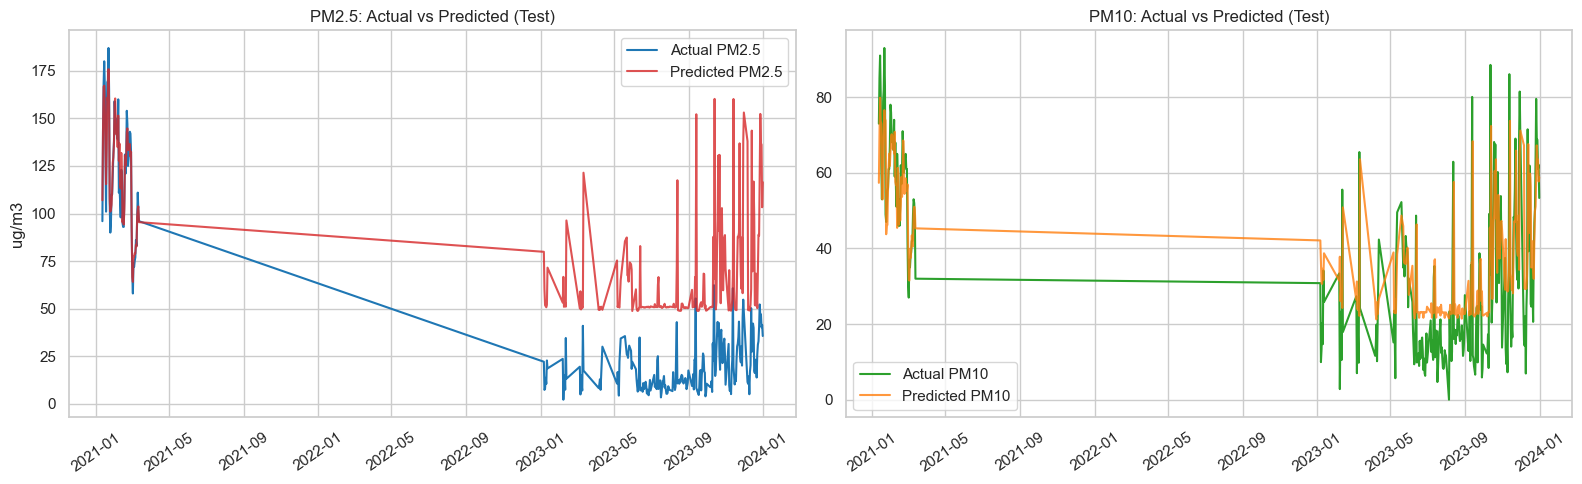

In [56]:
def regression_metrics(y_true: pd.Series, y_pred: np.ndarray) -> dict:
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }


def evaluate_model(model: Pipeline, X_part: pd.DataFrame, y_part: pd.Series, split_name: str, target_name: str) -> dict:
    preds = model.predict(X_part)
    metrics = regression_metrics(y_part, preds)
    return {
        "target": target_name,
        "split": split_name,
        **metrics,
    }


results = []
for split_name, X_part, y25_part, y10_part in [
    ("validation", X_val, y25_val, y10_val),
    ("test", X_test, y25_test, y10_test),
]:
    results.append(evaluate_model(pm25_model, X_part, y25_part, split_name, "pm25"))
    results.append(evaluate_model(pm10_model, X_part, y10_part, split_name, "pm10"))

metrics_df = pd.DataFrame(results)
display(metrics_df)

pm25_test_pred = pm25_model.predict(X_test)
pm10_test_pred = pm10_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)

axes[0].plot(date_test, y25_test.values, label="Actual PM2.5", color="#1f77b4")
axes[0].plot(date_test, pm25_test_pred, label="Predicted PM2.5", color="#d62728", alpha=0.8)
axes[0].set_title("PM2.5: Actual vs Predicted (Test)")
axes[0].set_ylabel("ug/m3")
axes[0].legend()

axes[1].plot(date_test, y10_test.values, label="Actual PM10", color="#2ca02c")
axes[1].plot(date_test, pm10_test_pred, label="Predicted PM10", color="#ff7f0e", alpha=0.8)
axes[1].set_title("PM10: Actual vs Predicted (Test)")
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## 9) บันทึกและโหลดโมเดล

บันทึกโมเดล, metadata, และทดสอบโหลดกลับมาใช้งานเพื่อยืนยันว่าพร้อมใช้งานจริง

In [57]:
models_dir = BASE_DIR / "models"
models_dir.mkdir(exist_ok=True)

pm25_model_path = models_dir / "pm25_model.joblib"
pm10_model_path = models_dir / "pm10_model.joblib"
metadata_path = models_dir / "training_metadata.json"

joblib.dump(pm25_model, pm25_model_path)
joblib.dump(pm10_model, pm10_model_path)

metadata = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "feature_columns": feature_cols,
    "training_rows": int(len(model_df)),
    "train_period": [str(date_train.min().date()), str(date_train.max().date())],
    "validation_period": [str(date_val.min().date()), str(date_val.max().date())],
    "test_period": [str(date_test.min().date()), str(date_test.max().date())],
    "metrics": metrics_df.to_dict(orient="records"),
    "external_dataset": "Open-Meteo Air Quality API (Bangkok)",
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

pm25_model_loaded = joblib.load(pm25_model_path)
pm10_model_loaded = joblib.load(pm10_model_path)

sample_X = X_test.head(3)
check_df = pd.DataFrame(
    {
        "pm25_pred_loaded": pm25_model_loaded.predict(sample_X),
        "pm10_pred_loaded": pm10_model_loaded.predict(sample_X),
    }
)

print("saved:", pm25_model_path)
print("saved:", pm10_model_path)
print("saved:", metadata_path)
display(check_df)

saved: c:\dev\New folder\models\pm25_model.joblib
saved: c:\dev\New folder\models\pm10_model.joblib
saved: c:\dev\New folder\models\training_metadata.json


,pm25_pred_loaded,pm10_pred_loaded
0,106.979756,57.348987
1,143.178753,69.993545
2,166.599398,79.833402


## 10) ทำนายผลด้วยข้อมูลใหม่

สร้างฟีเจอร์สำหรับวันถัดไปจากประวัติล่าสุด แล้วเรียก `predict()` เพื่อทำ forecast PM2.5/PM10

In [58]:
def build_next_day_feature_frame(
    history_df: pd.DataFrame,
    feature_columns: list[str],
    signal_columns: list[str],
) -> tuple[pd.Timestamp, pd.DataFrame]:
    hist = history_df.sort_values("date").copy()
    next_date = hist["date"].max() + pd.Timedelta(days=1)

    row: dict[str, float | int] = {}

    row["day_of_week"] = int(next_date.dayofweek)
    row["month"] = int(next_date.month)
    row["day_of_year"] = int(next_date.dayofyear)
    row["week_of_year"] = int(next_date.isocalendar().week)
    row["is_weekend"] = int(next_date.dayofweek in [5, 6])

    row["month_sin"] = float(np.sin(2 * np.pi * row["month"] / 12))
    row["month_cos"] = float(np.cos(2 * np.pi * row["month"] / 12))
    row["dow_sin"] = float(np.sin(2 * np.pi * row["day_of_week"] / 7))
    row["dow_cos"] = float(np.cos(2 * np.pi * row["day_of_week"] / 7))

    for col in signal_columns:
        if col in hist.columns:
            series = hist[col].dropna()
            row[f"{col}_lag1"] = float(series.iloc[-1]) if len(series) >= 1 else np.nan
            row[f"{col}_lag7"] = float(series.iloc[-7]) if len(series) >= 7 else np.nan
            row[f"{col}_roll7"] = float(series.tail(7).mean()) if len(series) >= 1 else np.nan

    next_X = pd.DataFrame([row])
    for col in feature_columns:
        if col not in next_X.columns:
            next_X[col] = np.nan

    next_X = next_X[feature_columns]
    return next_date, next_X


next_date, next_X = build_next_day_feature_frame(
    history_df=merged_daily,
    feature_columns=feature_cols,
    signal_columns=signal_cols,
)

next_pm25 = float(pm25_model_loaded.predict(next_X)[0])
next_pm10 = float(pm10_model_loaded.predict(next_X)[0])

forecast_df = pd.DataFrame(
    {
        "forecast_date": [next_date.date()],
        "pm25_forecast": [round(next_pm25, 2)],
        "pm10_forecast": [round(next_pm10, 2)],
    }
)

display(forecast_df)

,forecast_date,pm25_forecast,pm10_forecast
0,2024-01-01,93.72,47.11
